# Menzal Technologies Twin AI PoC

This notebook demonstrates a compact urban-planning workflow using the provided **Sentinel‑2C Level‑2A** and **Landsat‑9 Collection 2 Level‑2** products.

The PoC has three analytical layers:

1. **Surface characterization** — Sentinel‑2 spectral indices and unsupervised surface-regime clustering.
2. **Thermal modeling** — Landsat observed LST and a Random Forest model predicting LST from Sentinel‑2 features.
3. **Urban planning intelligence** — 250 m planning cells summarizing vegetation, thermal pressure, surface regimes, and a transparent prototype priority score.

The notebook keeps **observed data**, **supervised model predictions**, and **derived planning indicators** separate throughout.

## 1. Environment and configuration

In [1]:
from pathlib import Path
import json
import math
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import box
from osgeo import gdal, ogr

from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

gdal.UseExceptions()

RANDOM_STATE = 17
np.random.seed(RANDOM_STATE)

print("GDAL:", gdal.VersionInfo("--version"))

GDAL: GDAL 3.8.4, released 2024/02/08


### 1.1 Download data (first run only)

In [3]:
!unzip data/sample_input

Archive:  data/sample_input.zip
   creating: data/sample_input/
  inflating: data/sample_input/sample_extent.geojson  
   creating: data/sample_input/sentinel2/
  inflating: data/sample_input/sentinel2/T40RCN_20260815T064621_B11_20m.tif  
  inflating: data/sample_input/sentinel2/T40RCN_20260815T064621_B08_10m.tif  
  inflating: data/sample_input/sentinel2/T40RCN_20260815T064621_B02_10m.tif  
  inflating: data/sample_input/sentinel2/T40RCN_20260815T064621_B03_10m.tif  
  inflating: data/sample_input/sentinel2/T40RCN_20260815T064621_B04_10m.tif  
  inflating: data/sample_input/sentinel2/T40RCN_20260815T064621_B12_20m.tif  
  inflating: data/sample_input/sentinel2/MTD_MSIL2A.xml  
  inflating: data/sample_input/sentinel2/T40RCN_20260815T064621_SCL_20m.tif  
   creating: data/sample_input/landsat/
  inflating: data/sample_input/landsat/LC09_L2SP_160043_20260815_20260816_02_T1_ST_B10.TIF  
  inflating: data/sample_input/landsat/LC09_L2SP_160043_20260815_20260816_02_T1_MTL.xml  
  inflating:

### 1.2 Loading data

In [5]:
DATA_ROOT = Path("./data")

S2_ROOT = DATA_ROOT / "S2C_MSIL2A_20260815T064621_N0512_R020_T40RCN_20260815T114356.SAFE"
LANDSAT_ROOT = DATA_ROOT / "LC09_L2SP_160043_20260815_02_T1"
AOI_GEOJSON = DATA_ROOT / "P2_AOI_A_segme_FeaturesToJSO.geojson"

OUTPUT_DIR = Path("./outputs")
WORK_DIR = OUTPUT_DIR / "_work"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

# The supplied AOI polygons are used only as an anchor/reference.
# Modeling runs over a broader study context.
CONTEXT_BUFFER_M = 3000

# Planning/reporting grid per Abi I think
GRID_SIZE_M = 250

# Clustering
N_CLUSTERS = 5
MAX_CLUSTER_TRAIN_PIXELS = 200_000

# Random Forest validation
SPATIAL_BLOCK_M = 300
TEST_SIZE = 0.25

# Minimum usable EO support per planning cell
MIN_VALID_S2_FRACTION = 0.60
MIN_VALID_LST_FRACTION = 0.50

for p in [S2_ROOT, LANDSAT_ROOT, AOI_GEOJSON]:
    print(f"{p}: {'FOUND' if p.exists() else 'MISSING'}")

data/S2C_MSIL2A_20260815T064621_N0512_R020_T40RCN_20260815T114356.SAFE: MISSING
data/LC09_L2SP_160043_20260815_02_T1: MISSING
data/P2_AOI_A_segme_FeaturesToJSO.geojson: MISSING


## 2. Geospatial helpers

In [6]:
NODATA_FLOAT = -9999.0

def find_one(root: Path, pattern: str) -> Path:
    matches = list(root.rglob(pattern))
    if not matches:
        raise FileNotFoundError(f"No match for {pattern!r} under {root}")
    if len(matches) > 1:
        print(f"Warning: {len(matches)} matches for {pattern}; using {matches[0]}")
    return matches[0]


def read_array(path, dtype=None):
    ds = gdal.Open(str(path))
    arr = ds.GetRasterBand(1).ReadAsArray()
    if dtype is not None:
        arr = arr.astype(dtype)
    return arr


def bounds_from_ds(ds):
    gt = ds.GetGeoTransform()
    x0, y0 = gt[0], gt[3]
    x1 = x0 + gt[1] * ds.RasterXSize
    y1 = y0 + gt[5] * ds.RasterYSize
    return min(x0, x1), min(y0, y1), max(x0, x1), max(y0, y1)


def write_geotiff(path, array, ref_path, nodata=NODATA_FLOAT, gdal_type=gdal.GDT_Float32):
    path = Path(path)
    ref = gdal.Open(str(ref_path))
    driver = gdal.GetDriverByName("GTiff")
    out = driver.Create(
        str(path),
        ref.RasterXSize,
        ref.RasterYSize,
        1,
        gdal_type,
        options=["TILED=YES", "COMPRESS=DEFLATE"],
    )
    out.SetGeoTransform(ref.GetGeoTransform())
    out.SetProjection(ref.GetProjection())

    to_write = np.asarray(array).copy()
    if np.issubdtype(to_write.dtype, np.floating):
        to_write = np.where(np.isfinite(to_write), to_write, nodata)

    band = out.GetRasterBand(1)
    band.WriteArray(to_write)
    band.SetNoDataValue(float(nodata))
    band.FlushCache()

    out.FlushCache()
    out = None
    ref = None
    return path


def read_float_with_nodata(path):
    ds = gdal.Open(str(path))
    band = ds.GetRasterBand(1)
    arr = band.ReadAsArray().astype(np.float32)
    nd = band.GetNoDataValue()
    if nd is not None:
        arr[arr == nd] = np.nan
    return arr


def warp_cutline(src_path, dst_path, cutline_path, xres=None, yres=None,
                 resample_alg="bilinear", dst_nodata=NODATA_FLOAT):
    kwargs = dict(
        cutlineDSName=str(cutline_path),
        cropToCutline=True,
        resampleAlg=resample_alg,
        multithread=True,
        creationOptions=["TILED=YES", "COMPRESS=DEFLATE"],
        dstNodata=dst_nodata,
    )
    if xres is not None and yres is not None:
        kwargs.update(
            xRes=xres,
            yRes=yres,
            targetAlignedPixels=True,
        )
    gdal.Warp(str(dst_path), str(src_path), **kwargs)
    return Path(dst_path)


def warp_like(src_path, ref_path, dst_path, resample_alg="bilinear",
              src_nodata=None, dst_nodata=NODATA_FLOAT):
    ref = gdal.Open(str(ref_path))
    options = gdal.WarpOptions(
        format="GTiff",
        outputBounds=bounds_from_ds(ref),
        width=ref.RasterXSize,
        height=ref.RasterYSize,
        dstSRS=ref.GetProjection(),
        resampleAlg=resample_alg,
        srcNodata=src_nodata,
        dstNodata=dst_nodata,
        multithread=True,
        creationOptions=["TILED=YES", "COMPRESS=DEFLATE"],
    )
    gdal.Warp(str(dst_path), str(src_path), options=options)
    return Path(dst_path)


def make_buffered_context(aoi_path, output_path, buffer_m):
    gdf = gpd.read_file(aoi_path)
    metric_crs = gdf.estimate_utm_crs()
    metric = gdf.to_crs(metric_crs)
    geom = metric.geometry.union_all().buffer(buffer_m)

    out = gpd.GeoDataFrame(
        {"name": ["study_context"]},
        geometry=[geom],
        crs=metric_crs,
    ).to_crs(gdf.crs)

    out.to_file(output_path, driver="GeoJSON")
    return out


def make_regular_grid(context_gdf, cell_size_m=250):
    metric_crs = context_gdf.estimate_utm_crs()
    ctx = context_gdf.to_crs(metric_crs)
    geom = ctx.geometry.union_all()

    minx, miny, maxx, maxy = geom.bounds
    x0 = np.floor(minx / cell_size_m) * cell_size_m
    y0 = np.floor(miny / cell_size_m) * cell_size_m
    x1 = np.ceil(maxx / cell_size_m) * cell_size_m
    y1 = np.ceil(maxy / cell_size_m) * cell_size_m

    rows = []
    r = 0
    y = y0
    while y < y1:
        c = 0
        x = x0
        while x < x1:
            geom_cell = box(x, y, x + cell_size_m, y + cell_size_m)
            if geom_cell.within(geom):
                rows.append({
                    "grid_id": f"G{r:03d}_{c:03d}",
                    "row": r,
                    "col": c,
                    "geometry": geom_cell,
                })
            x += cell_size_m
            c += 1
        y += cell_size_m
        r += 1

    grid = gpd.GeoDataFrame(rows, crs=metric_crs)
    grid["cell_area_m2"] = grid.geometry.area
    return grid


def rasterize_feature_mask(vector_path, ref_raster, id_field, id_value):
    ref = gdal.Open(str(ref_raster))
    mem = gdal.GetDriverByName("MEM").Create(
        "", ref.RasterXSize, ref.RasterYSize, 1, gdal.GDT_Byte
    )
    mem.SetGeoTransform(ref.GetGeoTransform())
    mem.SetProjection(ref.GetProjection())
    mem.GetRasterBand(1).Fill(0)

    vds = ogr.Open(str(vector_path))
    layer = vds.GetLayer()

    if isinstance(id_value, str):
        layer.SetAttributeFilter(f"{id_field} = '{id_value}'")
    else:
        layer.SetAttributeFilter(f"{id_field} = {id_value}")

    gdal.RasterizeLayer(mem, [1], layer, burn_values=[1])
    mask = mem.GetRasterBand(1).ReadAsArray().astype(bool)

    vds = None
    mem = None
    return mask


def safe_ratio(num, den):
    out = np.full_like(num, np.nan, dtype=np.float32)
    ok = np.isfinite(num) & np.isfinite(den) & (np.abs(den) > 1e-6)
    out[ok] = num[ok] / den[ok]
    return out


def percentile_rank(values, score):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    if len(values) == 0 or not np.isfinite(score):
        return np.nan
    return float(np.mean(values <= score))

## 3. Data inventory and verified product metadata

The PoC uses two co-located EO products:

- **Sentinel‑2C Level‑2A** for surface reflectance and spectral characterization.
- **Landsat‑9 Collection 2 Level‑2 (L2SP)** for observed land-surface temperature.

The supplied Sentinel‑1 scene is intentionally excluded because it does not overlap with the rest of data (Why does it cover Egypt?).

### Helpers

In [ ]:
def local_name(tag):
    return tag.split("}")[-1]

def xml_first_local(root, name):
    for e in root.iter():
        if local_name(e.tag) == name:
            return e.text
    return None

In [ ]:
S2_MTD = find_one(S2_ROOT, "MTD_MSIL2A.xml")
LS_MTL = find_one(LANDSAT_ROOT, "*_MTL.xml")

s2_root_xml = ET.parse(S2_MTD).getroot()
ls_root_xml = ET.parse(LS_MTL).getroot()


inventory = pd.DataFrame([
    {
        "dataset": "Sentinel-2C",
        "product_id": xml_first_local(s2_root_xml, "PRODUCT_URI"),
        "processing_level": xml_first_local(s2_root_xml, "PROCESSING_LEVEL"),
        "acquisition_date": xml_first_local(s2_root_xml, "PRODUCT_START_TIME"),
        "role": "Surface reflectance, indices, clustering",
    },
    {
        "dataset": "Landsat-9",
        "product_id": xml_first_local(ls_root_xml, "LANDSAT_PRODUCT_ID"),
        "processing_level": xml_first_local(ls_root_xml, "PROCESSING_LEVEL"),
        "acquisition_date": xml_first_local(ls_root_xml, "DATE_ACQUIRED"),
        "role": "Observed LST target/reference",
    },
])

display(inventory)

,dataset,product_id,processing_level,acquisition_date,role
0,Sentinel-2C,S2C_MSIL2A_20260815T064621_N0512_R020_T40RCN_2...,Level-2A,2026-08-15T06:46:21.025Z,"Surface reflectance, indices, clustering"
1,Landsat-9,LC09_L2SP_160043_20260815_20260816_02_T1,L2SP,2026-08-15,Observed LST target/reference


## 4. Study context and 250 m planning grid

Supplied AOI segments: 5
Study buffer: 3000 m
Planning grid size: 250 m
Planning cells: 612


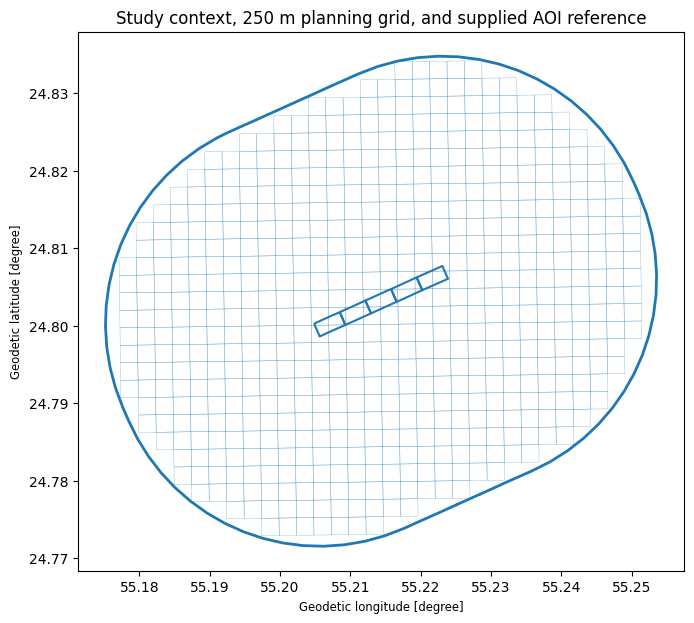

In [32]:
aoi = gpd.read_file(AOI_GEOJSON)

CONTEXT_GEOJSON = WORK_DIR / "study_context.geojson"
context = make_buffered_context(AOI_GEOJSON, CONTEXT_GEOJSON, CONTEXT_BUFFER_M)

planning_grid_metric = make_regular_grid(context, GRID_SIZE_M)
planning_grid = planning_grid_metric.to_crs(aoi.crs)

GRID_GEOJSON = WORK_DIR / "planning_grid.geojson"
planning_grid.to_file(GRID_GEOJSON, driver="GeoJSON")

print("Supplied AOI segments:", len(aoi))
print("Study buffer:", CONTEXT_BUFFER_M, "m")
print("Planning grid size:", GRID_SIZE_M, "m")
print("Planning cells:", len(planning_grid))

ax = context.boundary.plot(figsize=(9, 7), linewidth=2)
planning_grid.boundary.plot(ax=ax, linewidth=0.25, alpha=0.6)
aoi.boundary.plot(ax=ax, linewidth=1.5)
ax.set_title(f"Study context, {GRID_SIZE_M} m planning grid, and supplied AOI reference")
plt.show()

## 5. Sentinel‑2 preprocessing

Steps:

1. Read B02, B03, B04, B08 at 10 m and B11/B12 at 20 m.
2. Convert Level‑2A digital numbers to bottom-of-atmosphere reflectance using product metadata.
3. Align B11/B12 to the 10 m reference grid.
4. Align the categorical Scene Classification Layer (SCL) using nearest-neighbor resampling.
5. Mask invalid/cloud/shadow pixels.

Continuous bands use bilinear resampling; categorical masks use nearest-neighbor.

### Helpers

In [ ]:
def parse_s2_scaling(mtd_xml):
    root = ET.parse(mtd_xml).getroot()

    quant = None
    offsets = {}
    band_ids = {}

    for elem in root.iter():
        tag = local_name(elem.tag)
        if tag == "BOA_QUANTIFICATION_VALUE":
            quant = float(elem.text)
        elif tag == "BOA_ADD_OFFSET":
            offsets[int(elem.attrib["band_id"])] = float(elem.text)
        elif tag == "Spectral_Information":
            band_ids[elem.attrib["physicalBand"]] = int(elem.attrib["bandId"])

    return quant, offsets, band_ids

S2_QUANT, S2_OFFSETS, S2_BAND_IDS = parse_s2_scaling(S2_MTD)

def s2_to_reflectance(dn, band_name):
    band_id = S2_BAND_IDS[band_name] if band_name in S2_BAND_IDS else S2_BAND_IDS[band_name.replace("0","")]
    offset = S2_OFFSETS[band_id]
    out = (dn.astype(np.float32) + offset) / S2_QUANT
    out[(dn == 0) | (dn == 65535)] = np.nan
    return out

In [ ]:
s2_paths = {
    "B02": find_one(S2_ROOT, "*_B02_10m.tif"),
    "B03": find_one(S2_ROOT, "*_B03_10m.tif"),
    "B04": find_one(S2_ROOT, "*_B04_10m.tif"),
    "B08": find_one(S2_ROOT, "*_B08_10m.tif"),
    "B11": find_one(S2_ROOT, "*_B11_20m.tif"),
    "B12": find_one(S2_ROOT, "*_B12_20m.tif"),
    "SCL": find_one(S2_ROOT, "*_SCL_20m.tif"),
}

S2_REF = WORK_DIR / "s2_B04_10m_context.tif"
warp_cutline(
    s2_paths["B04"], S2_REF, CONTEXT_GEOJSON,
    xres=10, yres=10,
    resample_alg="bilinear",
    dst_nodata=0,
)

aligned_s2 = {"B04": S2_REF}

for b in ["B02", "B03", "B08"]:
    dst = WORK_DIR / f"s2_{b}_10m.tif"
    warp_like(s2_paths[b], S2_REF, dst, resample_alg="bilinear", dst_nodata=0)
    aligned_s2[b] = dst

for b in ["B11", "B12"]:
    dst = WORK_DIR / f"s2_{b}_to10m.tif"
    warp_like(s2_paths[b], S2_REF, dst, resample_alg="bilinear", dst_nodata=0)
    aligned_s2[b] = dst

SCL_10M = WORK_DIR / "s2_SCL_to10m.tif"
warp_like(s2_paths["SCL"], S2_REF, SCL_10M, resample_alg="near", dst_nodata=0)

B = {}
for b in ["B02", "B03", "B04", "B08", "B11", "B12"]:
    dn = read_array(aligned_s2[b], dtype=np.uint16)
    B[b] = s2_to_reflectance(dn, b)

scl = read_array(SCL_10M, dtype=np.uint8)

# Conservative exclusions:
# 0 no data, 1 saturated/defective, 2 dark/shadow-like,
# 3 cloud shadow, 8/9 cloud, 10 cirrus, 11 snow/ice.
bad_scl = np.isin(scl, [0, 1, 2, 3, 8, 9, 10, 11])

valid_s2 = ~bad_scl
for arr in B.values():
    valid_s2 &= np.isfinite(arr)

print("10 m raster shape:", B["B04"].shape)
print("Valid Sentinel-2 pixels:", int(valid_s2.sum()))
print("Valid fraction:", round(valid_s2.mean(), 4))

10 m raster shape: (700, 794)
Valid Sentinel-2 pixels: 419510
Valid fraction: 0.7548


## 6. Feature engineering

The feature stack contains six reflectance bands plus four spectral indices:

- **NDVI** — vegetation response.
- **NDBI** — built-up-sensitive SWIR/NIR contrast.
- **MNDWI** — water-sensitive green/SWIR contrast.
- **BSI** — bare-soil-sensitive spectral contrast.

These are treated as spectral features, not direct semantic land-cover labels.

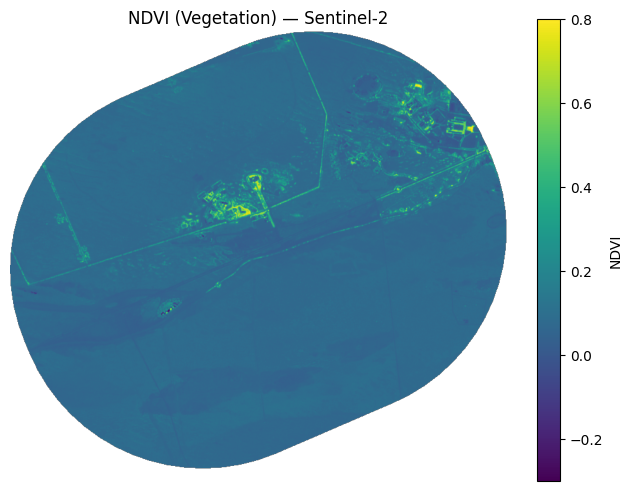

PosixPath('outputs/ndvi_10m.tif')

In [ ]:
NDVI = safe_ratio(B["B08"] - B["B04"], B["B08"] + B["B04"])
NDBI = safe_ratio(B["B11"] - B["B08"], B["B11"] + B["B08"])
MNDWI = safe_ratio(B["B03"] - B["B11"], B["B03"] + B["B11"])
BSI = safe_ratio(
    (B["B11"] + B["B04"]) - (B["B08"] + B["B02"]),
    (B["B11"] + B["B04"]) + (B["B08"] + B["B02"])
)

feature_10m = {
    **B,
    "NDVI": NDVI,
    "NDBI": NDBI,
    "MNDWI": MNDWI,
    "BSI": BSI,
}

for arr in feature_10m.values():
    valid_s2 &= np.isfinite(arr)

NDVI_MAP = np.where(valid_s2, NDVI, np.nan)

plt.figure(figsize=(8, 6))
im = plt.imshow(NDVI_MAP, vmin=-0.3, vmax=0.8)
plt.title("NDVI (Vegetation) — Sentinel-2")
plt.axis("off")
plt.colorbar(im, label="NDVI")
plt.show()

write_geotiff(OUTPUT_DIR / "ndvi_10m.tif", NDVI_MAP, S2_REF)

## 7. Unsupervised surface-regime clustering

A `MiniBatchKMeans` model groups Sentinel‑2 pixels with similar spectral behavior.

Pipeline:

`10 features → StandardScaler → MiniBatchKMeans(K=5)`

Because no independent land-cover labels are available, clusters are reported as **surface regimes**, not actually validated land-cover classes.

In [ ]:
import numpy as np
from scipy.ndimage import generic_filter

def majority_filter(mask, size=5):
    def mode(values):
        labels, counts = np.unique(values, return_counts=True)
        return labels[np.argmax(counts)]

    return generic_filter(mask, mode, size=size, mode="nearest")

,B02,B03,B04,B08,B11,B12,NDVI,NDBI,MNDWI,BSI,pixel_count
cluster,,,,,,,,,,,
0,0.203383,0.287324,0.371776,0.436681,0.568424,0.485858,0.080489,0.131157,-0.328658,0.189982,260893
1,0.106442,0.158378,0.181339,0.364049,0.379562,0.286664,0.338765,0.020325,-0.410973,0.084486,11021
2,0.172231,0.243335,0.312731,0.387670,0.512990,0.429542,0.107853,0.139386,-0.356792,0.191820,69567
3,0.252594,0.338010,0.419150,0.471961,0.557946,0.465976,0.059732,0.083386,-0.245850,0.148723,57745
4,0.192432,0.254783,0.303879,0.356539,0.387098,0.293786,0.080023,0.041042,-0.204786,0.114486,20284


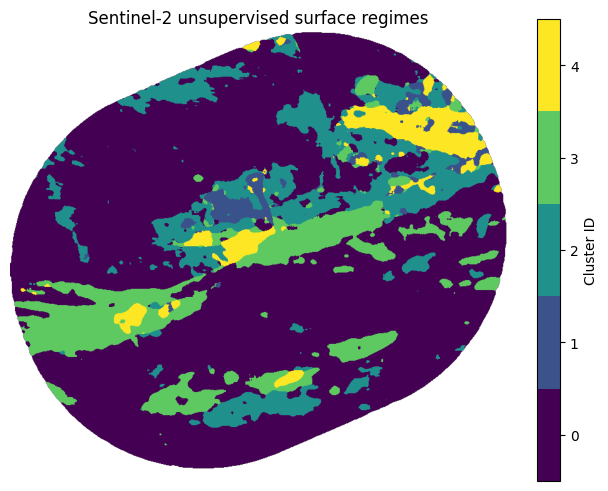

Vegetation-like cluster number: 1
Water-like cluster number: 4
Cluster training pixels: 200000


In [ ]:
cluster_features = [
    "B02", "B03", "B04", "B08", "B11", "B12",
    "NDVI", "NDBI", "MNDWI", "BSI"
]

X_cluster_all = np.column_stack([
    feature_10m[name][valid_s2]
    for name in cluster_features
])

if len(X_cluster_all) > MAX_CLUSTER_TRAIN_PIXELS:
    rng = np.random.default_rng(RANDOM_STATE)
    fit_idx = rng.choice(
        len(X_cluster_all),
        MAX_CLUSTER_TRAIN_PIXELS,
        replace=False
    )
    X_cluster_fit = X_cluster_all[fit_idx]
else:
    X_cluster_fit = X_cluster_all

cluster_scaler = StandardScaler()
X_cluster_fit_z = cluster_scaler.fit_transform(X_cluster_fit)

cluster_model = MiniBatchKMeans(
    n_clusters=N_CLUSTERS,
    batch_size=4096,
    n_init="auto",
    random_state=RANDOM_STATE,
)
cluster_model.fit(X_cluster_fit_z)

cluster_labels = cluster_model.predict(
    cluster_scaler.transform(X_cluster_all)
)
cluster_map = np.full(valid_s2.shape, -1, dtype=np.int16)
cluster_map[valid_s2] = cluster_labels
cluster_map = majority_filter(cluster_map,10)

cluster_df = pd.DataFrame(X_cluster_all, columns=cluster_features)
cluster_df["cluster"] = cluster_labels

cluster_profile = cluster_df.groupby("cluster")[cluster_features].mean()
cluster_profile["pixel_count"] = cluster_df.groupby("cluster").size()

display(cluster_profile)

plt.figure(figsize=(8, 6))
im = plt.imshow(np.where(cluster_map >= 0, cluster_map, np.nan))
plt.title("Sentinel-2 unsupervised surface regimes")
plt.axis("off")
cbar = plt.colorbar(
    im,
    ticks=np.arange(N_CLUSTERS),
    boundaries=np.arange(-0.5, N_CLUSTERS + 0.5, 1)
)

cbar.set_label("Cluster ID")
plt.show()

write_geotiff(
    OUTPUT_DIR / "surface_regimes_10m.tif",
    cluster_map,
    S2_REF,
    nodata=-1,
    gdal_type=gdal.GDT_Int16,
)

VEGETATION_CLUSTER = int(cluster_profile["NDVI"].idxmax())
WATER_CLUSTER = int(cluster_profile["MNDWI"].idxmax())

print("Vegetation-like cluster number:", VEGETATION_CLUSTER)
print("Water-like cluster number:", WATER_CLUSTER)
print("Cluster training pixels:", len(X_cluster_fit))

## 8. Landsat observed LST

`ST_B10` is already the Landsat Level‑2 surface-temperature product. The notebook:

1. crops it to the study context,
2. masks invalid/cloud/saturated pixels using QA,
3. applies the scene metadata scale and offset,
4. converts Kelvin to Celsius.

It does **not** recompute LST from raw thermal radiance.

Valid Landsat LST cells: 46616
LST min / median / max: 48.53 58.81 62.33


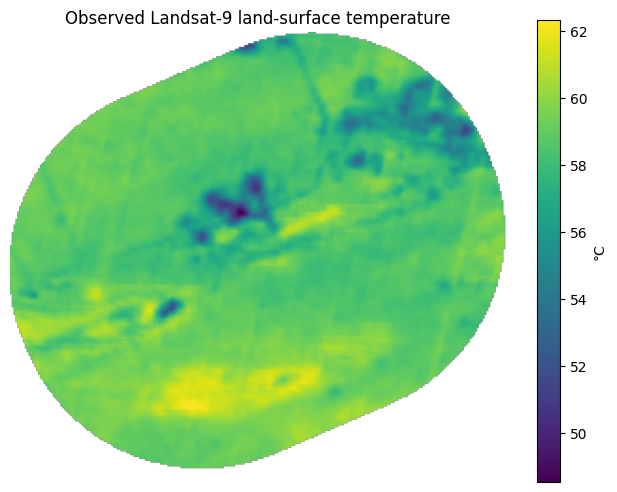

PosixPath('outputs/observed_lst_celsius_30m.tif')

In [ ]:
ls_paths = {
    "ST_B10": find_one(LANDSAT_ROOT, "*_ST_B10.TIF"),
    "QA_PIXEL": find_one(LANDSAT_ROOT, "*_QA_PIXEL.TIF"),
    "QA_RADSAT": find_one(LANDSAT_ROOT, "*_QA_RADSAT.TIF"),
}

ST_MULT = float(xml_first_local(ls_root_xml, "TEMPERATURE_MULT_BAND_ST_B10"))
ST_ADD = float(xml_first_local(ls_root_xml, "TEMPERATURE_ADD_BAND_ST_B10"))

LST_RAW = WORK_DIR / "landsat_ST_B10_context.tif"
QA_PIXEL = WORK_DIR / "landsat_QA_PIXEL_context.tif"
QA_RADSAT = WORK_DIR / "landsat_QA_RADSAT_context.tif"

warp_cutline(
    ls_paths["ST_B10"], LST_RAW, CONTEXT_GEOJSON,
    xres=30, yres=30, resample_alg="near", dst_nodata=0
)
warp_like(ls_paths["QA_PIXEL"], LST_RAW, QA_PIXEL, resample_alg="near", dst_nodata=0)
warp_like(ls_paths["QA_RADSAT"], LST_RAW, QA_RADSAT, resample_alg="near", dst_nodata=0)

st_dn = read_array(LST_RAW, dtype=np.uint16)
qa_pixel = read_array(QA_PIXEL, dtype=np.uint16)
qa_radsat = read_array(QA_RADSAT, dtype=np.uint16)

clear_mask = np.ones_like(qa_pixel, dtype=bool)
for bit in [0, 1, 2, 3, 4, 5]:
    clear_mask &= ((qa_pixel >> bit) & 1) == 0

clear_mask &= qa_radsat == 0
clear_mask &= st_dn != 0

lst_c = st_dn.astype(np.float32) * ST_MULT + ST_ADD - 273.15
lst_c[~clear_mask] = np.nan

print("Valid Landsat LST cells:", int(np.isfinite(lst_c).sum()))
print(
    "LST min / median / max:",
    round(float(np.nanmin(lst_c)), 2),
    round(float(np.nanmedian(lst_c)), 2),
    round(float(np.nanmax(lst_c)), 2),
)

plt.figure(figsize=(8, 6))
im = plt.imshow(lst_c)
plt.title("Observed Landsat-9 land-surface temperature")
plt.axis("off")
plt.colorbar(im, label="°C")
plt.show()

write_geotiff(OUTPUT_DIR / "observed_lst_celsius_30m.tif", lst_c, LST_RAW)

## 9. Visual context: Sentinel‑2 true colour and Landsat LST

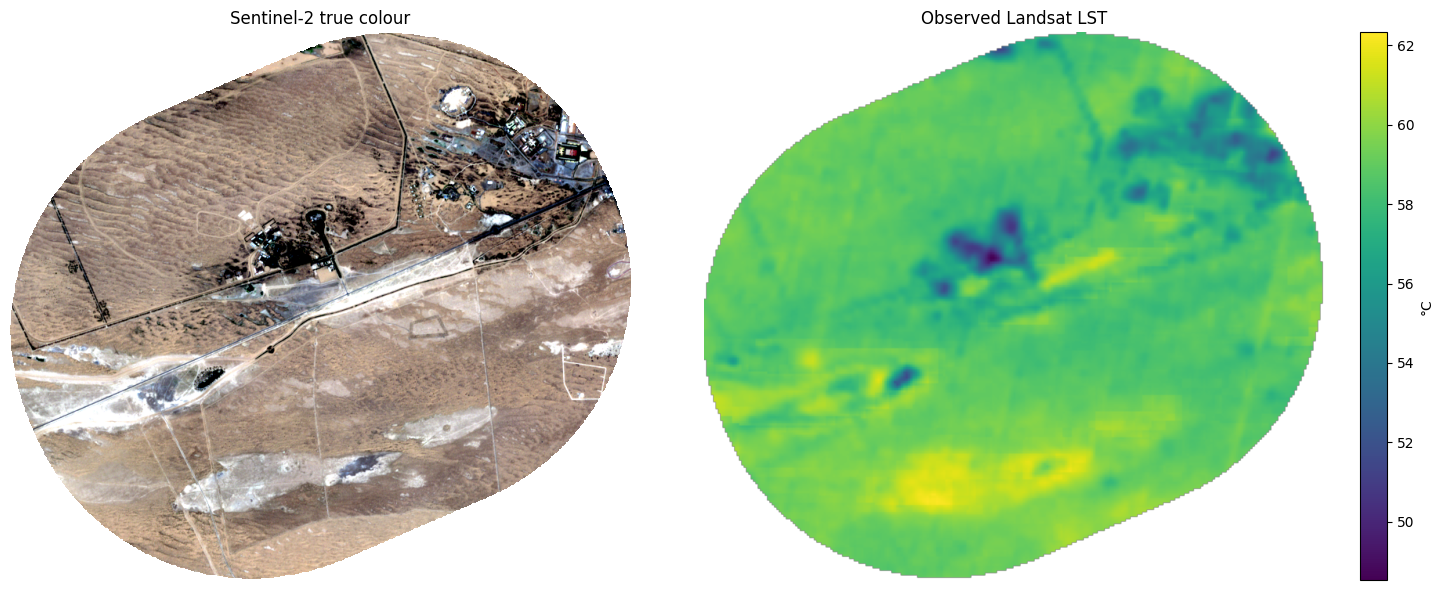

In [ ]:
def contrast_stretch(channel, valid_mask, low=2, high=98):
    vals = channel[valid_mask & np.isfinite(channel)]
    lo, hi = np.percentile(vals, [low, high])
    out = (channel - lo) / (hi - lo)
    return np.clip(out, 0, 1)

rgb = np.dstack([
    contrast_stretch(B["B04"], valid_s2),
    contrast_stretch(B["B03"], valid_s2),
    contrast_stretch(B["B02"], valid_s2),
])
rgb[~valid_s2] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 true colour")
axes[0].axis("off")

im = axes[1].imshow(lst_c)
axes[1].set_title("Observed Landsat LST")
axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.046, label="°C")

plt.tight_layout()
plt.show()

## 10. Harmonize Sentinel‑2 features to the Landsat 30 m modeling grid

The Random Forest target exists on the Landsat 30 m output grid. Sentinel‑2 continuous features are therefore aggregated to that grid using **average resampling**.



In [ ]:
feature_10m_paths = {}

for name, arr in feature_10m.items():
    masked = np.where(valid_s2, arr, np.nan).astype(np.float32)
    path = WORK_DIR / f"{name}_10m.tif"
    write_geotiff(path, masked, S2_REF)
    feature_10m_paths[name] = path

feature_30m = {}

for name, src in feature_10m_paths.items():
    dst = WORK_DIR / f"{name}_30m.tif"
    warp_like(
        src,
        LST_RAW,
        dst,
        resample_alg="average",
        src_nodata=NODATA_FLOAT,
        dst_nodata=NODATA_FLOAT,
    )
    feature_30m[name] = read_float_with_nodata(dst)

print("Landsat LST shape:", lst_c.shape)
print("Aggregated Sentinel-2 feature shape:", feature_30m["NDVI"].shape)

Landsat LST shape: (234, 265)
Aggregated Sentinel-2 feature shape: (234, 265)


## 11. Random Forest LST regression and spatial validation

### Target

- **X:** Sentinel‑2 reflectance + spectral features aggregated to 30 m.
- **y:** observed Landsat `ST_B10` LST in °C.

### Validation design

A random pixel split would leak information because neighboring satellite cells are spatially correlated. Instead, the study area is divided into approximately **300 m spatial blocks**. Entire blocks are assigned to train or test sets using `GroupShuffleSplit`.

The reported metrics therefore measure generalization to **withheld spatial blocks within this pilot area**.

,0
total_samples,46569.000000
train_samples,34899.000000
test_samples,11670.000000
train_fraction,0.749404
test_fraction,0.250596
total_spatial_groups,511.000000
train_spatial_groups,383.000000
test_spatial_groups,128.000000
spatial_block_m,300.000000
MAE_C,0.511859


,importance
B12,0.223077
B11,0.219581
NDBI,0.133648
BSI,0.113744
B04,0.070932
NDVI,0.070890
MNDWI,0.050995
B02,0.043389
B08,0.038462
B03,0.035281


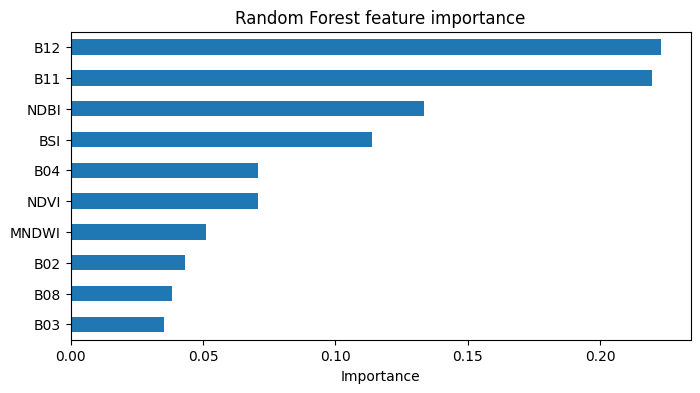

In [ ]:
reg_features = [
    "B02", "B03", "B04", "B08", "B11", "B12",
    "NDVI", "NDBI", "MNDWI", "BSI"
]

valid_ml = np.isfinite(lst_c)
for name in reg_features:
    valid_ml &= np.isfinite(feature_30m[name])

rows, cols = np.where(valid_ml)

X = np.column_stack([
    feature_30m[name][valid_ml]
    for name in reg_features
])
y = lst_c[valid_ml]

ref = gdal.Open(str(LST_RAW))
pixel_m = abs(ref.GetGeoTransform()[1])
block_px = max(1, int(round(SPATIAL_BLOCK_M / pixel_m)))

group_row = rows // block_px
group_col = cols // block_px
groups = group_row.astype(np.int64) * 1_000_000 + group_col.astype(np.int64)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

model = RandomForestRegressor(
    n_estimators=400,
    max_depth=14,
    min_samples_leaf=3,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
model.fit(X[train_idx], y[train_idx])

pred_test = model.predict(X[test_idx])

mae = mean_absolute_error(y[test_idx], pred_test)
rmse = mean_squared_error(y[test_idx], pred_test) ** 0.5
r2 = r2_score(y[test_idx], pred_test)
bias = float(np.mean(pred_test - y[test_idx]))

train_groups = np.unique(groups[train_idx])
test_groups = np.unique(groups[test_idx])

metrics = pd.DataFrame([{
    "total_samples": len(y),
    "train_samples": len(train_idx),
    "test_samples": len(test_idx),
    "train_fraction": len(train_idx) / len(y),
    "test_fraction": len(test_idx) / len(y),
    "total_spatial_groups": len(np.unique(groups)),
    "train_spatial_groups": len(train_groups),
    "test_spatial_groups": len(test_groups),
    "spatial_block_m": SPATIAL_BLOCK_M,
    "MAE_C": mae,
    "RMSE_C": rmse,
    "R^2": r2,
    "bias_C_pred_minus_obs": bias,
}])

display(metrics.T)

importance = pd.Series(
    model.feature_importances_,
    index=reg_features,
    name="importance",
).sort_values(ascending=False)

display(importance.to_frame())

plt.figure(figsize=(8, 4))
importance.sort_values().plot(kind="barh")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.show()

**Interpretation:** MAE, RMSE, R², and bias quantify how well Sentinel‑2-derived surface features reproduce withheld Landsat LST patterns.

## 12. Predicted LST and residual analysis

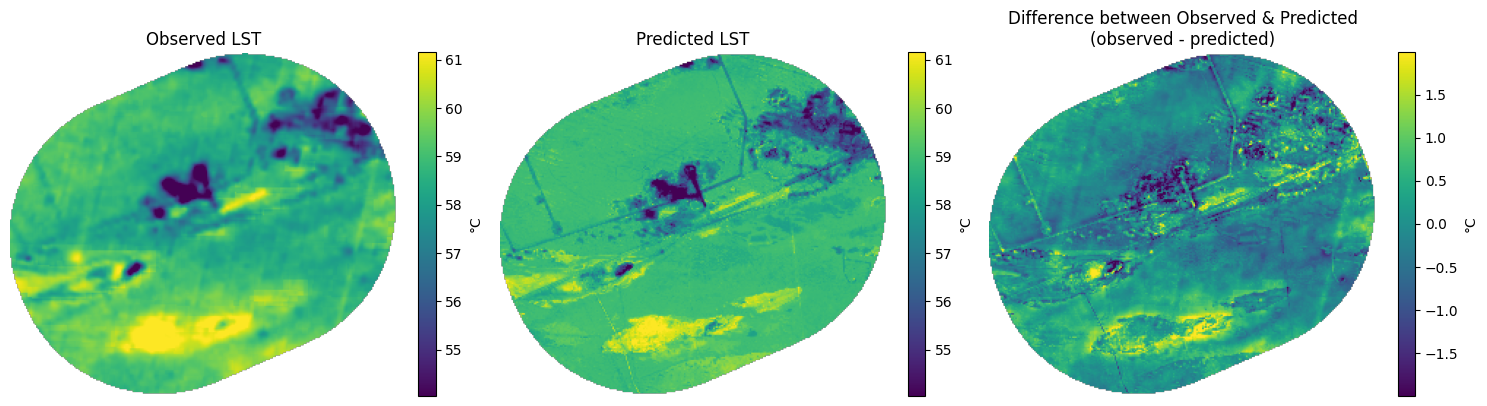

In [ ]:
# For direct observed-vs-predicted comparison, predict only where:
# (a) observed Landsat LST is valid, and
# (b) all Sentinel-2 predictors are valid.
valid_pred = np.isfinite(lst_c)

for name in reg_features:
    valid_pred &= np.isfinite(feature_30m[name])

X_pred = np.column_stack([
    feature_30m[name][valid_pred]
    for name in reg_features
])

pred_lst = np.full_like(lst_c, np.nan, dtype=np.float32)
pred_lst[valid_pred] = model.predict(X_pred).astype(np.float32)

residual = np.full_like(lst_c, np.nan, dtype=np.float32)
residual[valid_pred] = lst_c[valid_pred] - pred_lst[valid_pred]

write_geotiff(
    OUTPUT_DIR / "predicted_lst_from_sentinel2_30m.tif",
    pred_lst,
    LST_RAW,
)
write_geotiff(
    OUTPUT_DIR / "lst_residual_observed_minus_predicted_30m.tif",
    residual,
    LST_RAW,
)

all_temps = np.concatenate([
    lst_c[valid_pred],
    pred_lst[valid_pred],
])

vmin = np.nanpercentile(all_temps, 1)
vmax = np.nanpercentile(all_temps, 99)
rmax = np.nanpercentile(np.abs(residual[valid_pred]), 99)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

im0 = axes[0].imshow(lst_c, vmin=vmin, vmax=vmax)
axes[0].set_title("Observed LST")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046, label="°C")

im1 = axes[1].imshow(pred_lst, vmin=vmin, vmax=vmax)
axes[1].set_title("Predicted LST")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, label="°C")

im2 = axes[2].imshow(residual, vmin=-rmax, vmax=rmax)
axes[2].set_title("Difference between Observed & Predicted\n(observed - predicted)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, label="°C")

plt.tight_layout()
plt.show()

## 13. Relate surface regimes to observed thermal behavior

In [ ]:
cluster_fraction_30m = {}

for k in range(N_CLUSTERS):
    one_hot = np.where(
        valid_s2,
        (cluster_map == k).astype(np.float32),
        np.nan
    )

    src = WORK_DIR / f"cluster_{k}_10m.tif"
    dst = WORK_DIR / f"cluster_{k}_fraction_30m.tif"

    write_geotiff(src, one_hot, S2_REF)

    warp_like(
        src,
        LST_RAW,
        dst,
        resample_alg="average",
        src_nodata=NODATA_FLOAT,
        dst_nodata=NODATA_FLOAT,
    )

    cluster_fraction_30m[k] = read_float_with_nodata(dst)

stack = np.stack(
    [cluster_fraction_30m[k] for k in range(N_CLUSTERS)],
    axis=-1
)

all_nan = np.all(~np.isfinite(stack), axis=-1)
safe_stack = np.where(np.isfinite(stack), stack, -np.inf)

dominant_cluster_30m = np.argmax(safe_stack, axis=-1).astype(np.int16)
dominant_cluster_30m[all_nan] = -1

cluster_thermal = []

for k in range(N_CLUSTERS):
    mask = (dominant_cluster_30m == k) & np.isfinite(lst_c)
    cluster_thermal.append({
        "cluster": k,
        "mean_LST_C": float(np.nanmean(lst_c[mask])) if mask.any() else np.nan,
        "cells": int(mask.sum()),
    })

cluster_thermal = pd.DataFrame(cluster_thermal).set_index("cluster")
display(cluster_thermal)

HEAT_ASSOCIATED_CLUSTER = int(cluster_thermal["mean_LST_C"].idxmax())

print("Cluster most associated with higher observed LST:", HEAT_ASSOCIATED_CLUSTER)

,mean_LST_C,cells
cluster,,
0,58.931767,29655
1,55.223354,1249
2,58.474926,7368
3,59.086430,6151
4,56.451721,2146


Cluster most associated with higher observed LST: 3


## 14. 250 m urban-planning indicators

Each 250 m cell summarizes:

- observed thermal conditions,
- vegetation-like surface fraction,
- cluster composition,
- predicted LST,
- model residual,
- thermal pressure relative to the broader study context.

The **planning-priority score** is intentionally simple:

- 50% thermal-pressure percentile,
- 30% vegetation deficit,
- 20% heat-associated surface fraction.


,grid_id,mean_lst_c,p90_lst_c,hot_area_fraction,thermal_pressure_pct,vegetation_like_fraction,heat_assoc_surface_fraction,dominant_cluster,mean_pred_lst_c,mean_residual_c,planning_priority_score,s2_valid_fraction,lst_valid_fraction,cluster_0_fraction,cluster_1_fraction,cluster_2_fraction,cluster_3_fraction,cluster_4_fraction
0,G004_012,61.795589,62.172100,1.000000,99.815514,0.0,0.8336,3,60.659859,1.135727,96.579757,1.0,1.0,0.1488,0.0,0.0176,0.8336,0.0000
1,G004_009,60.690430,61.193504,1.000000,96.580573,0.0,0.8704,3,60.285072,0.405361,95.698287,1.0,1.0,0.1296,0.0,0.0000,0.8704,0.0000
2,G004_010,61.156303,61.587257,1.000000,98.245238,0.0,0.8160,3,60.262005,0.894298,95.442619,1.0,1.0,0.1840,0.0,0.0000,0.8160,0.0000
3,G009_002,60.318504,60.470917,1.000000,94.716406,0.0,0.8976,3,60.138062,0.180444,95.310203,1.0,1.0,0.1024,0.0,0.0000,0.8976,0.0000
4,G009_003,59.923996,60.251823,0.791667,91.284108,0.0,0.9440,3,59.848495,0.075500,94.522054,1.0,1.0,0.0352,0.0,0.0192,0.9440,0.0016
5,G004_011,61.901585,62.198761,1.000000,99.856273,0.0,0.7296,3,60.877945,1.023633,94.520136,1.0,1.0,0.2704,0.0,0.0000,0.7296,0.0000
6,G009_005,60.026501,60.508514,0.925926,92.382444,0.0,0.9056,3,59.742210,0.284278,94.303222,1.0,1.0,0.0448,0.0,0.0464,0.9056,0.0032
7,G008_023,59.861572,59.995819,0.944444,90.460357,0.0,0.9248,3,59.956604,-0.095038,93.726178,1.0,1.0,0.0752,0.0,0.0000,0.9248,0.0000
8,G009_001,60.526657,60.875294,1.000000,95.838339,0.0,0.7808,3,60.207321,0.319342,93.535169,1.0,1.0,0.2192,0.0,0.0000,0.7808,0.0000
9,G005_016,61.024979,61.335693,1.000000,97.794749,0.0,0.7248,3,59.859455,1.165523,93.393374,1.0,1.0,0.1312,0.0,0.1424,0.7248,0.0016


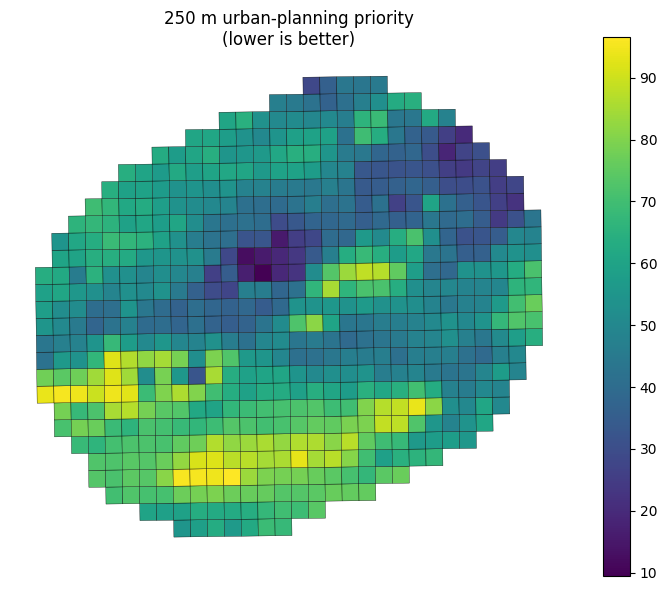

In [ ]:
s2_crs = gdal.Open(str(S2_REF)).GetProjection()
ls_crs = gdal.Open(str(LST_RAW)).GetProjection()

grid_s2 = planning_grid.to_crs(s2_crs)
grid_ls = planning_grid.to_crs(ls_crs)

GRID_S2 = WORK_DIR / "planning_grid_s2.geojson"
GRID_LS = WORK_DIR / "planning_grid_landsat.geojson"

grid_s2.to_file(GRID_S2, driver="GeoJSON")
grid_ls.to_file(GRID_LS, driver="GeoJSON")

context_lst = lst_c[np.isfinite(lst_c)]
hot_threshold = float(np.nanpercentile(context_lst, 85))

rows_out = []

for gid in planning_grid["grid_id"]:
    m10 = rasterize_feature_mask(GRID_S2, S2_REF, "grid_id", gid)
    m30 = rasterize_feature_mask(GRID_LS, LST_RAW, "grid_id", gid)

    total10 = int(m10.sum())
    total30 = int(m30.sum())

    v10 = m10 & valid_s2
    v30 = m30 & np.isfinite(lst_c)

    s2_valid_fraction = v10.sum() / total10 if total10 else np.nan
    lst_valid_fraction = v30.sum() / total30 if total30 else np.nan

    if (
        not np.isfinite(s2_valid_fraction)
        or not np.isfinite(lst_valid_fraction)
        or s2_valid_fraction < MIN_VALID_S2_FRACTION
        or lst_valid_fraction < MIN_VALID_LST_FRACTION
    ):
        continue

    cluster_fracs = {
        k: float(np.mean(cluster_map[v10] == k))
        for k in range(N_CLUSTERS)
    }

    dominant_cluster = max(cluster_fracs, key=cluster_fracs.get)
    vegetation_frac = cluster_fracs[VEGETATION_CLUSTER]
    heat_surface_frac = cluster_fracs[HEAT_ASSOCIATED_CLUSTER]

    mean_lst = float(np.nanmean(lst_c[v30]))
    p90_lst = float(np.nanpercentile(lst_c[v30], 90))
    hot_area_fraction = float(np.mean(lst_c[v30] >= hot_threshold))

    pred_mask = m30 & np.isfinite(pred_lst)
    res_mask = m30 & np.isfinite(residual)

    mean_pred_lst = float(np.nanmean(pred_lst[pred_mask])) if pred_mask.any() else np.nan
    mean_residual = float(np.nanmean(residual[res_mask])) if res_mask.any() else np.nan

    thermal_pressure = percentile_rank(context_lst, mean_lst)
    vegetation_deficit = 1.0 - vegetation_frac

    priority_score = 100 * (
        0.50 * thermal_pressure
        + 0.30 * vegetation_deficit
        + 0.20 * heat_surface_frac
    )

    row = {
        "grid_id": gid,
        "mean_lst_c": mean_lst,
        "p90_lst_c": p90_lst,
        "hot_area_fraction": hot_area_fraction,
        "thermal_pressure_pct": 100 * thermal_pressure,
        "vegetation_like_fraction": vegetation_frac,
        "heat_assoc_surface_fraction": heat_surface_frac,
        "dominant_cluster": int(dominant_cluster),
        "mean_pred_lst_c": mean_pred_lst,
        "mean_residual_c": mean_residual,
        "planning_priority_score": priority_score,
        "s2_valid_fraction": s2_valid_fraction,
        "lst_valid_fraction": lst_valid_fraction,
    }

    for k, frac in cluster_fracs.items():
        row[f"cluster_{k}_fraction"] = frac

    rows_out.append(row)

grid_indicators = (
    pd.DataFrame(rows_out)
    .sort_values("planning_priority_score", ascending=False)
    .reset_index(drop=True)
)

grid_result = planning_grid.merge(
    grid_indicators,
    on="grid_id",
    how="inner"
)

display(grid_indicators.head(20))

ax = grid_result.plot(
    column="planning_priority_score",
    legend=True,
    figsize=(9, 7),
    edgecolor="black",
    linewidth=0.25,
)
ax.set_title("250 m urban-planning priority\n(lower is better)")
ax.set_axis_off()
plt.show()

## 15. Main PoC outputs

The six primary spatial outputs are:

1. **NDVI**
2. **Surface-regime clustering**
3. **Observed LST**
4. **Predicted LST**
5. **Observed − predicted residual**
6. **250 m planning-priority map**

In [ ]:
OUT_GRID_GEOJSON = OUTPUT_DIR / "urban_planning_grid_indicators.geojson"
OUT_GRID_CSV = OUTPUT_DIR / "urban_planning_grid_indicators.csv"
OUT_METRICS_CSV = OUTPUT_DIR / "random_forest_validation_metrics.csv"
OUT_CLUSTER_PROFILE_CSV = OUTPUT_DIR / "cluster_profiles.csv"

grid_result.to_file(OUT_GRID_GEOJSON, driver="GeoJSON")
grid_indicators.to_csv(OUT_GRID_CSV, index=False)
metrics.to_csv(OUT_METRICS_CSV, index=False)
cluster_profile.to_csv(OUT_CLUSTER_PROFILE_CSV)

print("Exports:")
for p in [
    OUTPUT_DIR / "ndvi_10m.tif",
    OUTPUT_DIR / "surface_regimes_10m.tif",
    OUTPUT_DIR / "observed_lst_celsius_30m.tif",
    OUTPUT_DIR / "predicted_lst_from_sentinel2_30m.tif",
    OUTPUT_DIR / "lst_residual_observed_minus_predicted_30m.tif",
    OUT_GRID_GEOJSON,
    OUT_GRID_CSV,
    OUT_METRICS_CSV,
    OUT_CLUSTER_PROFILE_CSV,
]:
    print(" -", p)

Exports:
 - outputs/ndvi_10m.tif
 - outputs/surface_regimes_10m.tif
 - outputs/observed_lst_celsius_30m.tif
 - outputs/predicted_lst_from_sentinel2_30m.tif
 - outputs/lst_residual_observed_minus_predicted_30m.tif
 - outputs/urban_planning_grid_indicators.geojson
 - outputs/urban_planning_grid_indicators.csv
 - outputs/random_forest_validation_metrics.csv
 - outputs/cluster_profiles.csv


## 16. gIQ, data accuracy, validation scope, and limitations

### Data provenance

- **Sentinel‑2C:** official Level‑2A product; product identity and processing level are read from its supplied metadata.
- **Landsat‑9:** USGS Collection 2 Level‑2 Science Product (`L2SP`); `ST_B10` is used as the observed LST layer.
- **gIQ:** the platform through which the challenge data were provided/accessed. This notebook does not independently audit any additional platform-side transformation unless recorded in the supplied metadata.
- **Sentinel‑1:** excluded because the supplied scene does not spatially overlap the UAE study area.

### What is validated

- Random Forest performance is evaluated on **withheld spatial blocks** using MAE, RMSE, R², and bias.
- This validates the model's ability to reproduce withheld **Landsat LST patterns within this pilot**.

### Concrete limitations

- No independent field temperature or external thermal reference is available; Landsat LST itself is not independently validated here.
- One observation period does not support urban-growth or temporal-change claims.
- No independent land-cover labels are available; K-means outputs are **surface regimes**, not validated semantic classes.
- Landsat thermal information is coarser than Sentinel‑2; do not make building-scale thermal claims.
- LST is surface-skin temperature, not air temperature or human heat exposure.
- Feature importance and surface/LST relationships are associative, not causal.
- The 250 m planning-priority score is a transparent PoC heuristic, not a validated risk score.
- Results demonstrate feasibility for this pilot area; citywide or cross-city generalization is not established.

## 17. Save a compact provenance record

In [ ]:
provenance = {
    "sentinel2_product": xml_first_local(s2_root_xml, "PRODUCT_URI"),
    "sentinel2_processing_level": xml_first_local(s2_root_xml, "PROCESSING_LEVEL"),
    "landsat_product": xml_first_local(ls_root_xml, "LANDSAT_PRODUCT_ID"),
    "landsat_processing_level": xml_first_local(ls_root_xml, "PROCESSING_LEVEL"),
    "study_context_buffer_m": CONTEXT_BUFFER_M,
    "planning_grid_m": GRID_SIZE_M,
    "n_clusters": N_CLUSTERS,
    "random_forest": {
        "n_estimators": 400,
        "max_depth": 14,
        "min_samples_leaf": 3,
        "max_features": "sqrt",
        "random_state": RANDOM_STATE,
    },
    "validation": {
        "split": "GroupShuffleSplit",
        "spatial_block_m": SPATIAL_BLOCK_M,
        "test_size": TEST_SIZE,
        "metrics": metrics.iloc[0].to_dict(),
    },
    "sentinel1_status": "Excluded: supplied scene does not overlap UAE pilot",
}

with open(OUTPUT_DIR / "provenance.json", "w", encoding="utf-8") as f:
    json.dump(provenance, f, indent=2, default=float)

print("Saved:", OUTPUT_DIR / "provenance.json")

Saved: outputs/provenance.json


## 18. Optional sample-input reproducibility run

If `./data/sample_input/` exists, the notebook runs a compact version of the same analysis using only the cropped repository sample:

- Sentinel-2 reflectance + NDVI/NDBI/MNDWI/BSI
- unsupervised surface-regime clustering
- Landsat observed LST
- Random Forest LST prediction with spatial holdout
- residual analysis
- 250 m planning-priority indicators

The sample run writes its example deliverables to `./results/`.

If the sample directory is absent, this section is skipped.

In [16]:
SAMPLE_INPUT_ROOT = Path("./data/sample_input")
SAMPLE_RESULT_DIR = Path("./results")
SAMPLE_WORK_DIR = SAMPLE_RESULT_DIR / "_sample_work"

SAMPLE_RUN_AVAILABLE = False

if not SAMPLE_INPUT_ROOT.exists():
    print(
        "Sample-input directory not found. "
        "Skipping the optional sample reproducibility run."
    )
else:
    print("Sample-input directory found:", SAMPLE_INPUT_ROOT.resolve())

    SAMPLE_RESULT_DIR.mkdir(parents=True, exist_ok=True)
    SAMPLE_WORK_DIR.mkdir(parents=True, exist_ok=True)

    sample_s2_root = SAMPLE_INPUT_ROOT / "sentinel2"
    sample_ls_root = SAMPLE_INPUT_ROOT / "landsat"
    sample_extent_path = SAMPLE_INPUT_ROOT / "sample_extent.geojson"

    sample_s2_paths = {
        "B02": find_one(sample_s2_root, "*_B02_10m.tif"),
        "B03": find_one(sample_s2_root, "*_B03_10m.tif"),
        "B04": find_one(sample_s2_root, "*_B04_10m.tif"),
        "B08": find_one(sample_s2_root, "*_B08_10m.tif"),
        "B11": find_one(sample_s2_root, "*_B11_20m.tif"),
        "B12": find_one(sample_s2_root, "*_B12_20m.tif"),
        "SCL": find_one(sample_s2_root, "*_SCL_20m.tif"),
    }

    sample_ls_paths = {
        "ST_B10": find_one(sample_ls_root, "*_ST_B10.TIF"),
        "QA_PIXEL": find_one(sample_ls_root, "*_QA_PIXEL.TIF"),
        "QA_RADSAT": find_one(sample_ls_root, "*_QA_RADSAT.TIF"),
    }

    sample_s2_mtd = find_one(sample_s2_root, "MTD_MSIL2A.xml")
    sample_ls_mtl = find_one(sample_ls_root, "*_MTL.xml")

    if not sample_extent_path.exists():
        raise FileNotFoundError(
            f"Required sample extent not found: {sample_extent_path}"
        )

    sample_s2_quant, sample_s2_offsets, sample_s2_band_ids = parse_s2_scaling(
        sample_s2_mtd
    )

    def sample_s2_to_reflectance(dn, band_name):
        band_id = (
            sample_s2_band_ids[band_name]
            if band_name in sample_s2_band_ids
            else sample_s2_band_ids[band_name.replace("0", "")]
        )
        offset = sample_s2_offsets[band_id]
        out = (dn.astype(np.float32) + offset) / sample_s2_quant
        out[(dn == 0) | (dn == 65535)] = np.nan
        return out

    sample_ls_xml_root = ET.parse(sample_ls_mtl).getroot()

    def sample_xml_first_local(root, name):
        for elem in root.iter():
            if local_name(elem.tag) == name:
                return elem.text
        return None

    sample_st_mult = float(
        sample_xml_first_local(
            sample_ls_xml_root,
            "TEMPERATURE_MULT_BAND_ST_B10",
        )
    )
    sample_st_add = float(
        sample_xml_first_local(
            sample_ls_xml_root,
            "TEMPERATURE_ADD_BAND_ST_B10",
        )
    )

    sample_s2_ref = sample_s2_paths["B04"]

    sample_aligned_s2 = {
        "B02": sample_s2_paths["B02"],
        "B03": sample_s2_paths["B03"],
        "B04": sample_s2_paths["B04"],
        "B08": sample_s2_paths["B08"],
    }

    for band_name in ["B11", "B12"]:
        dst_path = SAMPLE_WORK_DIR / f"{band_name}_to10m.tif"
        warp_like(
            sample_s2_paths[band_name],
            sample_s2_ref,
            dst_path,
            resample_alg="bilinear",
            src_nodata=0,
            dst_nodata=0,
        )
        sample_aligned_s2[band_name] = dst_path

    sample_scl_10m = SAMPLE_WORK_DIR / "SCL_to10m.tif"
    warp_like(
        sample_s2_paths["SCL"],
        sample_s2_ref,
        sample_scl_10m,
        resample_alg="near",
        src_nodata=0,
        dst_nodata=0,
    )

    sample_B = {}
    for band_name in ["B02", "B03", "B04", "B08", "B11", "B12"]:
        dn = read_array(sample_aligned_s2[band_name], dtype=np.uint16)
        sample_B[band_name] = sample_s2_to_reflectance(dn, band_name)

    sample_scl = read_array(sample_scl_10m, dtype=np.uint8)

    sample_bad_scl = np.isin(
        sample_scl,
        [0, 1, 2, 3, 8, 9, 10, 11],
    )

    sample_valid_s2 = ~sample_bad_scl
    for arr in sample_B.values():
        sample_valid_s2 &= np.isfinite(arr)

    sample_NDVI = safe_ratio(
        sample_B["B08"] - sample_B["B04"],
        sample_B["B08"] + sample_B["B04"],
    )
    sample_NDBI = safe_ratio(
        sample_B["B11"] - sample_B["B08"],
        sample_B["B11"] + sample_B["B08"],
    )
    sample_MNDWI = safe_ratio(
        sample_B["B03"] - sample_B["B11"],
        sample_B["B03"] + sample_B["B11"],
    )
    sample_BSI = safe_ratio(
        (sample_B["B11"] + sample_B["B04"])
        - (sample_B["B08"] + sample_B["B02"]),
        (sample_B["B11"] + sample_B["B04"])
        + (sample_B["B08"] + sample_B["B02"]),
    )

    sample_feature_10m = {
        **sample_B,
        "NDVI": sample_NDVI,
        "NDBI": sample_NDBI,
        "MNDWI": sample_MNDWI,
        "BSI": sample_BSI,
    }

    for arr in sample_feature_10m.values():
        sample_valid_s2 &= np.isfinite(arr)

    sample_ndvi_map = np.where(
        sample_valid_s2,
        sample_NDVI,
        np.nan,
    )

    sample_cluster_features = [
        "B02", "B03", "B04", "B08", "B11", "B12",
        "NDVI", "NDBI", "MNDWI", "BSI",
    ]

    sample_X_cluster = np.column_stack([
        sample_feature_10m[name][sample_valid_s2]
        for name in sample_cluster_features
    ])

    if len(sample_X_cluster) > MAX_CLUSTER_TRAIN_PIXELS:
        sample_rng = np.random.default_rng(RANDOM_STATE)
        sample_fit_idx = sample_rng.choice(
            len(sample_X_cluster),
            MAX_CLUSTER_TRAIN_PIXELS,
            replace=False,
        )
        sample_X_cluster_fit = sample_X_cluster[sample_fit_idx]
    else:
        sample_X_cluster_fit = sample_X_cluster

    sample_cluster_scaler = StandardScaler()
    sample_X_cluster_fit_z = sample_cluster_scaler.fit_transform(
        sample_X_cluster_fit
    )

    sample_cluster_model = MiniBatchKMeans(
        n_clusters=N_CLUSTERS,
        batch_size=4096,
        n_init="auto",
        random_state=RANDOM_STATE,
    )
    sample_cluster_model.fit(sample_X_cluster_fit_z)

    sample_cluster_labels = sample_cluster_model.predict(
        sample_cluster_scaler.transform(sample_X_cluster)
    )

    sample_cluster_map = np.full(
        sample_valid_s2.shape,
        -1,
        dtype=np.int16,
    )
    sample_cluster_map[sample_valid_s2] = sample_cluster_labels

    sample_cluster_df = pd.DataFrame(
        sample_X_cluster,
        columns=sample_cluster_features,
    )
    sample_cluster_df["cluster"] = sample_cluster_labels

    sample_cluster_profile = sample_cluster_df.groupby("cluster")[
        sample_cluster_features
    ].mean()

    sample_vegetation_cluster = int(
        sample_cluster_profile["NDVI"].idxmax()
    )

    sample_lst_ref = sample_ls_paths["ST_B10"]

    sample_st_dn = read_array(
        sample_ls_paths["ST_B10"],
        dtype=np.uint16,
    )
    sample_qa_pixel = read_array(
        sample_ls_paths["QA_PIXEL"],
        dtype=np.uint16,
    )
    sample_qa_radsat = read_array(
        sample_ls_paths["QA_RADSAT"],
        dtype=np.uint16,
    )

    sample_clear = np.ones_like(
        sample_qa_pixel,
        dtype=bool,
    )

    for bit in [0, 1, 2, 3, 4, 5]:
        sample_clear &= ((sample_qa_pixel >> bit) & 1) == 0

    sample_clear &= sample_qa_radsat == 0
    sample_clear &= sample_st_dn != 0

    sample_lst_c = (
        sample_st_dn.astype(np.float32)
        * sample_st_mult
        + sample_st_add
        - 273.15
    )
    sample_lst_c[~sample_clear] = np.nan

    sample_feature_10m_paths = {}
    sample_feature_30m = {}

    for name, arr in sample_feature_10m.items():
        src_path = SAMPLE_WORK_DIR / f"{name}_10m.tif"

        write_geotiff(
            src_path,
            np.where(sample_valid_s2, arr, np.nan).astype(np.float32),
            sample_s2_ref,
        )

        sample_feature_10m_paths[name] = src_path

        dst_path = SAMPLE_WORK_DIR / f"{name}_30m.tif"

        warp_like(
            src_path,
            sample_lst_ref,
            dst_path,
            resample_alg="average",
            src_nodata=NODATA_FLOAT,
            dst_nodata=NODATA_FLOAT,
        )

        sample_feature_30m[name] = read_float_with_nodata(dst_path)

    sample_reg_features = [
        "B02", "B03", "B04", "B08", "B11", "B12",
        "NDVI", "NDBI", "MNDWI", "BSI",
    ]

    sample_valid_ml = np.isfinite(sample_lst_c)

    for name in sample_reg_features:
        sample_valid_ml &= np.isfinite(sample_feature_30m[name])

    sample_rows, sample_cols = np.where(sample_valid_ml)

    sample_X = np.column_stack([
        sample_feature_30m[name][sample_valid_ml]
        for name in sample_reg_features
    ])
    sample_y = sample_lst_c[sample_valid_ml]

    sample_ref_ds = gdal.Open(str(sample_lst_ref))
    sample_pixel_m = abs(sample_ref_ds.GetGeoTransform()[1])
    sample_ref_ds = None

    sample_block_px = max(
        1,
        int(round(SPATIAL_BLOCK_M / sample_pixel_m)),
    )

    sample_group_row = sample_rows // sample_block_px
    sample_group_col = sample_cols // sample_block_px

    sample_groups = (
        sample_group_row.astype(np.int64) * 1_000_000
        + sample_group_col.astype(np.int64)
    )

    sample_splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
    )

    sample_train_idx, sample_test_idx = next(
        sample_splitter.split(
            sample_X,
            sample_y,
            groups=sample_groups,
        )
    )

    sample_model = RandomForestRegressor(
        n_estimators=400,
        max_depth=14,
        min_samples_leaf=3,
        max_features="sqrt",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )

    sample_model.fit(
        sample_X[sample_train_idx],
        sample_y[sample_train_idx],
    )

    sample_pred_test = sample_model.predict(
        sample_X[sample_test_idx]
    )

    sample_mae = mean_absolute_error(
        sample_y[sample_test_idx],
        sample_pred_test,
    )
    sample_rmse = mean_squared_error(
        sample_y[sample_test_idx],
        sample_pred_test,
    ) ** 0.5
    sample_r2 = r2_score(
        sample_y[sample_test_idx],
        sample_pred_test,
    )
    sample_bias = float(
        np.mean(
            sample_pred_test
            - sample_y[sample_test_idx]
        )
    )

    sample_metrics = pd.DataFrame([{
        "total_samples": len(sample_y),
        "train_samples": len(sample_train_idx),
        "test_samples": len(sample_test_idx),
        "train_fraction": len(sample_train_idx) / len(sample_y),
        "test_fraction": len(sample_test_idx) / len(sample_y),
        "total_spatial_groups": len(np.unique(sample_groups)),
        "train_spatial_groups": len(
            np.unique(sample_groups[sample_train_idx])
        ),
        "test_spatial_groups": len(
            np.unique(sample_groups[sample_test_idx])
        ),
        "spatial_block_m": SPATIAL_BLOCK_M,
        "MAE_C": sample_mae,
        "RMSE_C": sample_rmse,
        "R^2": sample_r2,
        "bias_C_pred_minus_obs": sample_bias,
    }])

    sample_importance = pd.Series(
        sample_model.feature_importances_,
        index=sample_reg_features,
        name="importance",
    ).sort_values(ascending=False)

    sample_valid_pred = np.isfinite(sample_lst_c)

    for name in sample_reg_features:
        sample_valid_pred &= np.isfinite(sample_feature_30m[name])

    sample_X_pred = np.column_stack([
        sample_feature_30m[name][sample_valid_pred]
        for name in sample_reg_features
    ])

    sample_pred_lst = np.full_like(
        sample_lst_c,
        np.nan,
        dtype=np.float32,
    )

    sample_pred_lst[sample_valid_pred] = sample_model.predict(
        sample_X_pred
    ).astype(np.float32)

    sample_residual = np.full_like(
        sample_lst_c,
        np.nan,
        dtype=np.float32,
    )

    sample_residual[sample_valid_pred] = (
        sample_lst_c[sample_valid_pred]
        - sample_pred_lst[sample_valid_pred]
    )

    # Relate clusters to observed LST
    sample_cluster_fraction_30m = {}

    for k in range(N_CLUSTERS):
        one_hot = np.where(
            sample_valid_s2,
            (sample_cluster_map == k).astype(np.float32),
            np.nan,
        )

        src_path = SAMPLE_WORK_DIR / f"cluster_{k}_10m.tif"
        dst_path = SAMPLE_WORK_DIR / f"cluster_{k}_fraction_30m.tif"

        write_geotiff(
            src_path,
            one_hot,
            sample_s2_ref,
        )

        warp_like(
            src_path,
            sample_lst_ref,
            dst_path,
            resample_alg="average",
            src_nodata=NODATA_FLOAT,
            dst_nodata=NODATA_FLOAT,
        )

        sample_cluster_fraction_30m[k] = read_float_with_nodata(
            dst_path
        )

    sample_cluster_stack = np.stack(
        [
            sample_cluster_fraction_30m[k]
            for k in range(N_CLUSTERS)
        ],
        axis=-1,
    )

    sample_all_nan = np.all(
        ~np.isfinite(sample_cluster_stack),
        axis=-1,
    )

    sample_safe_stack = np.where(
        np.isfinite(sample_cluster_stack),
        sample_cluster_stack,
        -np.inf,
    )

    sample_dominant_cluster_30m = np.argmax(
        sample_safe_stack,
        axis=-1,
    ).astype(np.int16)

    sample_dominant_cluster_30m[sample_all_nan] = -1

    sample_cluster_thermal_rows = []

    for k in range(N_CLUSTERS):
        mask = (
            (sample_dominant_cluster_30m == k)
            & np.isfinite(sample_lst_c)
        )

        sample_cluster_thermal_rows.append({
            "cluster": k,
            "mean_LST_C": (
                float(np.nanmean(sample_lst_c[mask]))
                if mask.any()
                else np.nan
            ),
            "cells": int(mask.sum()),
        })

    sample_cluster_thermal = pd.DataFrame(
        sample_cluster_thermal_rows
    ).set_index("cluster")

    sample_heat_cluster = int(
        sample_cluster_thermal["mean_LST_C"].idxmax()
    )

    sample_extent = gpd.read_file(sample_extent_path)

    sample_planning_grid = make_regular_grid(
        sample_extent,
        GRID_SIZE_M,
    )

    sample_s2_crs = gdal.Open(
        str(sample_s2_ref)
    ).GetProjection()

    sample_ls_crs = gdal.Open(
        str(sample_lst_ref)
    ).GetProjection()

    sample_grid_s2 = sample_planning_grid.to_crs(sample_s2_crs)
    sample_grid_ls = sample_planning_grid.to_crs(sample_ls_crs)

    sample_grid_s2_path = SAMPLE_WORK_DIR / "planning_grid_s2.geojson"
    sample_grid_ls_path = SAMPLE_WORK_DIR / "planning_grid_landsat.geojson"

    sample_grid_s2.to_file(
        sample_grid_s2_path,
        driver="GeoJSON",
    )
    sample_grid_ls.to_file(
        sample_grid_ls_path,
        driver="GeoJSON",
    )

    sample_context_lst = sample_lst_c[
        np.isfinite(sample_lst_c)
    ]

    sample_hot_threshold = float(
        np.nanpercentile(sample_context_lst, 85)
    )

    sample_rows_out = []

    for gid in sample_planning_grid["grid_id"]:
        m10 = rasterize_feature_mask(
            sample_grid_s2_path,
            sample_s2_ref,
            "grid_id",
            gid,
        )

        m30 = rasterize_feature_mask(
            sample_grid_ls_path,
            sample_lst_ref,
            "grid_id",
            gid,
        )

        total10 = int(m10.sum())
        total30 = int(m30.sum())

        v10 = m10 & sample_valid_s2
        v30 = m30 & np.isfinite(sample_lst_c)

        sample_s2_valid_fraction = (
            v10.sum() / total10
            if total10
            else np.nan
        )

        sample_lst_valid_fraction = (
            v30.sum() / total30
            if total30
            else np.nan
        )

        if (
            not np.isfinite(sample_s2_valid_fraction)
            or not np.isfinite(sample_lst_valid_fraction)
            or sample_s2_valid_fraction < MIN_VALID_S2_FRACTION
            or sample_lst_valid_fraction < MIN_VALID_LST_FRACTION
        ):
            continue

        sample_cluster_fracs = {
            k: float(
                np.mean(
                    sample_cluster_map[v10] == k
                )
            )
            for k in range(N_CLUSTERS)
        }

        sample_dominant_cluster = max(
            sample_cluster_fracs,
            key=sample_cluster_fracs.get,
        )

        sample_vegetation_frac = sample_cluster_fracs[
            sample_vegetation_cluster
        ]

        sample_heat_surface_frac = sample_cluster_fracs[
            sample_heat_cluster
        ]

        sample_mean_lst = float(
            np.nanmean(sample_lst_c[v30])
        )

        sample_p90_lst = float(
            np.nanpercentile(
                sample_lst_c[v30],
                90,
            )
        )

        sample_hot_area_fraction = float(
            np.mean(
                sample_lst_c[v30]
                >= sample_hot_threshold
            )
        )

        sample_pred_mask = (
            m30 & np.isfinite(sample_pred_lst)
        )

        sample_res_mask = (
            m30 & np.isfinite(sample_residual)
        )

        sample_mean_pred_lst = (
            float(
                np.nanmean(
                    sample_pred_lst[sample_pred_mask]
                )
            )
            if sample_pred_mask.any()
            else np.nan
        )

        sample_mean_residual = (
            float(
                np.nanmean(
                    sample_residual[sample_res_mask]
                )
            )
            if sample_res_mask.any()
            else np.nan
        )

        sample_thermal_pressure = percentile_rank(
            sample_context_lst,
            sample_mean_lst,
        )

        sample_vegetation_deficit = (
            1.0 - sample_vegetation_frac
        )

        sample_priority_score = 100 * (
            0.50 * sample_thermal_pressure
            + 0.30 * sample_vegetation_deficit
            + 0.20 * sample_heat_surface_frac
        )

        row = {
            "grid_id": gid,
            "mean_lst_c": sample_mean_lst,
            "p90_lst_c": sample_p90_lst,
            "hot_area_fraction": sample_hot_area_fraction,
            "thermal_pressure_pct": 100 * sample_thermal_pressure,
            "vegetation_like_fraction": sample_vegetation_frac,
            "heat_assoc_surface_fraction": sample_heat_surface_frac,
            "dominant_cluster": int(sample_dominant_cluster),
            "mean_pred_lst_c": sample_mean_pred_lst,
            "mean_residual_c": sample_mean_residual,
            "planning_priority_score": sample_priority_score,
            "s2_valid_fraction": sample_s2_valid_fraction,
            "lst_valid_fraction": sample_lst_valid_fraction,
        }

        for k, frac in sample_cluster_fracs.items():
            row[f"cluster_{k}_fraction"] = frac

        sample_rows_out.append(row)

    sample_grid_indicators = (
        pd.DataFrame(sample_rows_out)
        .sort_values(
            "planning_priority_score",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    sample_grid_result = sample_planning_grid.merge(
        sample_grid_indicators,
        on="grid_id",
        how="inner",
    )

    sample_metrics.to_csv(
        SAMPLE_RESULT_DIR / "sample_validation_metrics.csv",
        index=False,
    )

    sample_grid_indicators.to_csv(
        SAMPLE_RESULT_DIR / "sample_grid_indicators.csv",
        index=False,
    )

    sample_grid_result.to_file(
        SAMPLE_RESULT_DIR / "sample_grid_indicators.geojson",
        driver="GeoJSON",
    )

    SAMPLE_RUN_AVAILABLE = True

    print("\nSample run completed.")
    display(sample_metrics.T)
    print(
        "Vegetation-like cluster:",
        sample_vegetation_cluster,
    )
    print(
        "Heat-associated cluster:",
        sample_heat_cluster,
    )
    print(
        "Planning cells retained:",
        len(sample_grid_result),
    )

Sample-input directory found: /content/data/sample_input

Sample run completed.


,0
total_samples,22500.000000
train_samples,16800.000000
test_samples,5700.000000
train_fraction,0.746667
test_fraction,0.253333
total_spatial_groups,225.000000
train_spatial_groups,168.000000
test_spatial_groups,57.000000
spatial_block_m,300.000000
MAE_C,0.577577


Vegetation-like cluster: 4
Heat-associated cluster: 0
Planning cells retained: 289


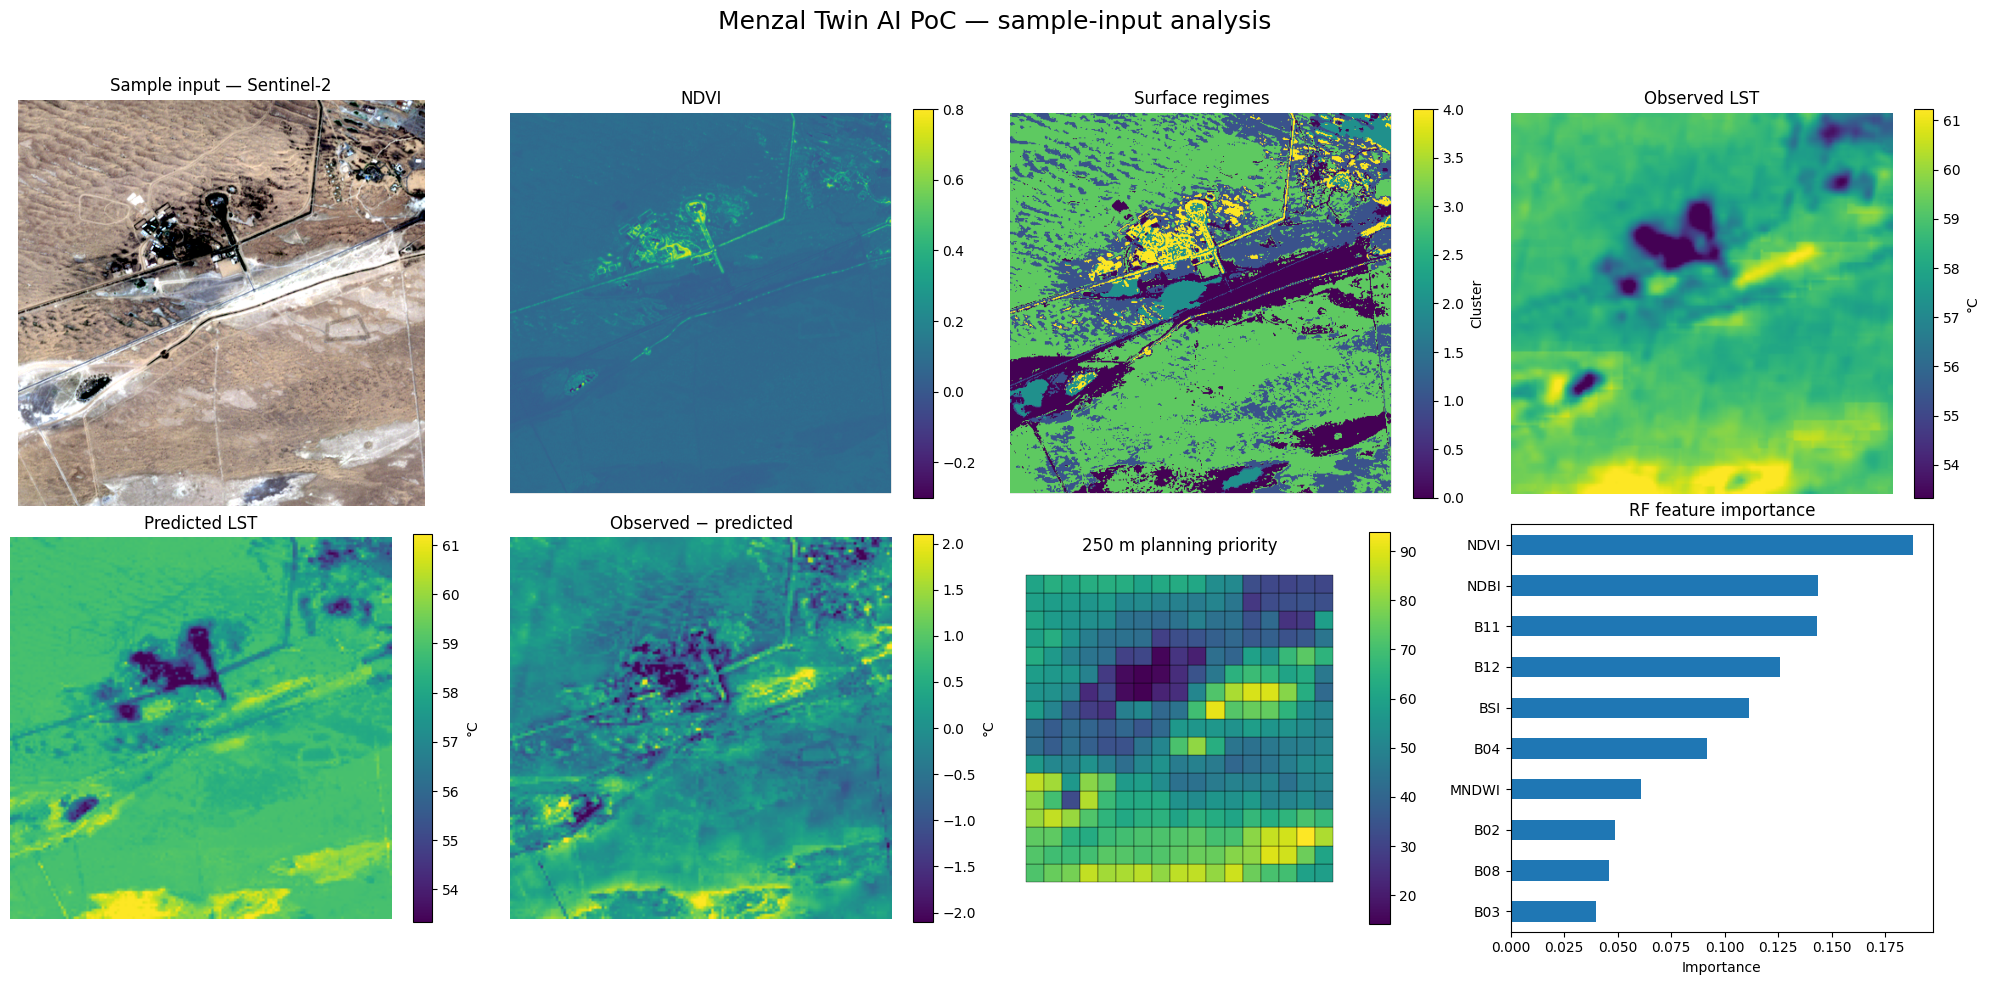

Saved example output: results/example_output.png
Validation: MAE=0.578 °C, RMSE=0.825 °C, R²=0.745, bias=-0.004 °C


In [17]:
# Generate one example output
if not SAMPLE_RUN_AVAILABLE:
    print("No sample result generated because data/sample_input was not available.")
else:
    def sample_contrast_stretch(channel, valid_mask, low=2, high=98):
        vals = channel[
            valid_mask & np.isfinite(channel)
        ]
        lo, hi = np.percentile(
            vals,
            [low, high],
        )
        out = (channel - lo) / (hi - lo)
        return np.clip(out, 0, 1)

    sample_rgb = np.dstack([
        sample_contrast_stretch(
            sample_B["B04"],
            sample_valid_s2,
        ),
        sample_contrast_stretch(
            sample_B["B03"],
            sample_valid_s2,
        ),
        sample_contrast_stretch(
            sample_B["B02"],
            sample_valid_s2,
        ),
    ])

    sample_rgb[~sample_valid_s2] = np.nan

    sample_all_temps = np.concatenate([
        sample_lst_c[sample_valid_pred],
        sample_pred_lst[sample_valid_pred],
    ])

    sample_vmin = np.nanpercentile(
        sample_all_temps,
        1,
    )
    sample_vmax = np.nanpercentile(
        sample_all_temps,
        99,
    )

    sample_rmax = np.nanpercentile(
        np.abs(
            sample_residual[sample_valid_pred]
        ),
        99,
    )

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(20, 10),
    )

    # 1. True colour
    axes[0, 0].imshow(sample_rgb)
    axes[0, 0].set_title("Sample input — Sentinel-2")
    axes[0, 0].axis("off")

    # 2. NDVI
    im = axes[0, 1].imshow(
        sample_ndvi_map,
        vmin=-0.3,
        vmax=0.8,
    )
    axes[0, 1].set_title("NDVI")
    axes[0, 1].axis("off")
    plt.colorbar(
        im,
        ax=axes[0, 1],
        fraction=0.046,
    )

    # 3. Clustering
    im = axes[0, 2].imshow(
        np.where(
            sample_cluster_map >= 0,
            sample_cluster_map,
            np.nan,
        )
    )
    axes[0, 2].set_title("Surface regimes")
    axes[0, 2].axis("off")
    plt.colorbar(
        im,
        ax=axes[0, 2],
        fraction=0.046,
        label="Cluster",
    )

    # 4. Observed LST
    im = axes[0, 3].imshow(
        sample_lst_c,
        vmin=sample_vmin,
        vmax=sample_vmax,
    )
    axes[0, 3].set_title("Observed LST")
    axes[0, 3].axis("off")
    plt.colorbar(
        im,
        ax=axes[0, 3],
        fraction=0.046,
        label="°C",
    )

    # 5. Predicted LST
    im = axes[1, 0].imshow(
        sample_pred_lst,
        vmin=sample_vmin,
        vmax=sample_vmax,
    )
    axes[1, 0].set_title("Predicted LST")
    axes[1, 0].axis("off")
    plt.colorbar(
        im,
        ax=axes[1, 0],
        fraction=0.046,
        label="°C",
    )

    # 6. Residual
    im = axes[1, 1].imshow(
        sample_residual,
        vmin=-sample_rmax,
        vmax=sample_rmax,
    )
    axes[1, 1].set_title("Observed − predicted")
    axes[1, 1].axis("off")
    plt.colorbar(
        im,
        ax=axes[1, 1],
        fraction=0.046,
        label="°C",
    )

    # 7. Planning priority
    sample_grid_result.plot(
        column="planning_priority_score",
        legend=True,
        ax=axes[1, 2],
        edgecolor="black",
        linewidth=0.25,
    )
    axes[1, 2].set_title("250 m planning priority")
    axes[1, 2].axis("off")

    # 8. Feature importance
    sample_importance.sort_values().plot(
        kind="barh",
        ax=axes[1, 3],
    )
    axes[1, 3].set_title("RF feature importance")
    axes[1, 3].set_xlabel("Importance")

    fig.suptitle(
        "Menzal Twin AI PoC — sample-input analysis",
        fontsize=18,
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.96]
    )

    sample_example_output = (
        SAMPLE_RESULT_DIR
        / "example_output.png"
    )

    plt.savefig(
        sample_example_output,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved example output:", sample_example_output)
    print(
        "Validation:",
        f"MAE={sample_mae:.3f} °C,",
        f"RMSE={sample_rmse:.3f} °C,",
        f"R²={sample_r2:.3f},",
        f"bias={sample_bias:.3f} °C",
    )